# 04 · Neural network for 60-day churn
Predicts `churned_next_60d` from `customers.csv` + `orders.csv`. Steps: build features, train a PyTorch network with early stopping, compare with a gradient-boosting baseline.



## 1. Data and features

In [5]:
import numpy as np, pandas as pd, torch, torch.nn as nn, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
D = "C:/Users/lakshraj computer/Downloads/QuickCart_Assessment_Keval_Chauhan/quickcart_data/"
cust = pd.read_csv(D + "customers.csv")
orders = pd.read_csv(D + "orders.csv", parse_dates=["order_ts"]).drop_duplicates()
y = pd.read_csv(D + "churn_labels.csv")

# --- cleaning ---
cust["city"] = cust.city.str.strip().str.title().replace({"Bangalore": "Bengaluru"})
cust["age"] = cust.age.where(cust.age.between(10, 90))            # 0 and 999 are invalid
cust["tenure_days"] = (orders.order_ts.max() - pd.to_datetime(cust.signup_date)).dt.days
orders["basket_value"] = orders.basket_value.where(orders.basket_value > 0)   # negatives are errors
orders["discount_amt"] = orders.discount_amt.clip(lower=0)
orders["delivery_minutes"] = orders.delivery_minutes.clip(upper=120)         # extreme outliers

# --- order features per customer ---
orders["bad"] = (orders.status != "delivered").astype(int)
g = orders.groupby("customer_id")
f = pd.DataFrame({
    "n_orders": g.size(), "avg_basket": g.basket_value.mean(), "avg_items": g.items_count.mean(),
    "avg_discount": g.discount_amt.mean(), "avg_distance": g.distance_km.mean(),
    "avg_delivery_min": g.delivery_minutes.mean(), "bad_order_rate": g.bad.mean(),
    "days_since_last": (orders.order_ts.max() - g.order_ts.max()).dt.days,
    "orders_last_30d": orders[orders.order_ts >= orders.order_ts.max() - pd.Timedelta(days=30)].groupby("customer_id").size(),
}).reset_index()

df = cust.merge(f, on="customer_id", how="left").merge(y, on="customer_id")
df["no_orders"] = df.n_orders.isna().astype(int)
df[["n_orders", "orders_last_30d"]] = df[["n_orders", "orders_last_30d"]].fillna(0)
X = pd.get_dummies(df.drop(columns=["customer_id", "signup_date", "account_status", "churned_next_60d"]),
                   columns=["city", "gender", "plan_type", "acquisition_channel"], dtype=float)
target = df.churned_next_60d.values
print(X.shape, "churn rate:", target.mean().round(3))

(4000, 28) churn rate: 0.088


## 2. Split, scale, build and train the network

In [6]:
# 80/20 test split, then 12.5% of train as validation (= 10% of all rows)
X_tr, X_te, y_tr, y_te = train_test_split(X, target, test_size=0.2, stratify=target, random_state=SEED)
X_tr, X_va, y_tr, y_va = train_test_split(X_tr, y_tr, test_size=0.125, stratify=y_tr, random_state=SEED)

med = X_tr.median()                                  # fill missing values with train medians
sc = StandardScaler().fit(X_tr.fillna(med))          # scaler fitted on train only
prep = lambda a: torch.tensor(sc.transform(a.fillna(med)), dtype=torch.float32)
Xt, Xv, Xe = prep(X_tr), prep(X_va), prep(X_te)
yt, yv = (torch.tensor(a, dtype=torch.float32) for a in (y_tr, y_va))

net = nn.Sequential(
    nn.Linear(X.shape[1], 64), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(32, 1))
pos_weight = torch.tensor((1 - y_tr.mean()) / y_tr.mean())      # weighted loss for imbalance
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)

best, wait, patience, hist, best_state = float("inf"), 0, 15, {"train": [], "val": []}, None
for epoch in range(200):
    net.train()
    for i in torch.randperm(len(Xt)).split(128):                # mini-batches
        opt.zero_grad(); loss_fn(net(Xt[i]).squeeze(1), yt[i]).backward(); opt.step()
    net.eval()
    with torch.no_grad():
        tl = loss_fn(net(Xt).squeeze(1), yt).item(); vl = loss_fn(net(Xv).squeeze(1), yv).item()
    hist["train"].append(tl); hist["val"].append(vl)
    if vl < best - 1e-4: best, wait, best_state = vl, 0, {k: v.clone() for k, v in net.state_dict().items()}
    else:
        wait += 1
        if wait >= patience: break
net.load_state_dict(best_state)                                 # restore best epoch
print(f"stopped at epoch {epoch + 1}, best epoch {epoch + 1 - wait}")

stopped at epoch 36, best epoch 21


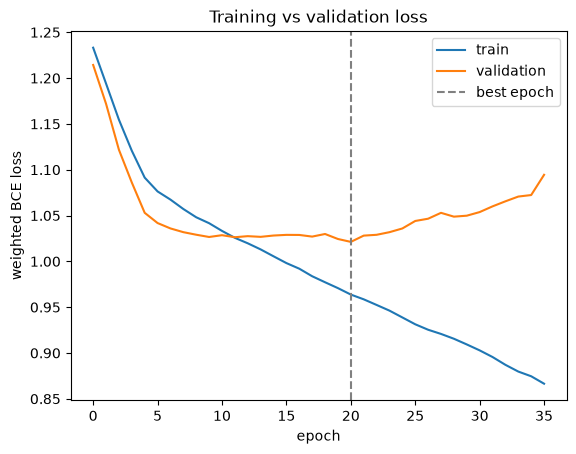

In [7]:
plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="validation")
plt.axvline(len(hist["val"]) - 1 - wait, ls="--", c="gray", label="best epoch")
plt.xlabel("epoch"); plt.ylabel("weighted BCE loss"); plt.title("Training vs validation loss"); plt.legend(); plt.show()

## 3. Compare on the held-out test set

In [8]:
net.eval()
with torch.no_grad(): p_nn = torch.sigmoid(net(Xe).squeeze(1)).numpy()

# Stand-in for the Part E best model: replace with your own model/scores if different.
gb = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED).fit(X_tr, y_tr)
p_gb = gb.predict_proba(X_te)[:, 1]

res = pd.DataFrame({"ROC-AUC": [roc_auc_score(y_te, p_gb), roc_auc_score(y_te, p_nn)],
                    "PR-AUC":  [average_precision_score(y_te, p_gb), average_precision_score(y_te, p_nn)]},
                   index=["Gradient boosting (Part E stand-in)", "Neural network"]).round(3)
print(res); print("Baseline PR-AUC of a random model =", y_te.mean().round(3))

                                     ROC-AUC  PR-AUC
Gradient boosting (Part E stand-in)    0.691   0.292
Neural network                         0.771   0.345
Baseline PR-AUC of a random model = 0.088


**Decision.** On the test set the neural network scores ROC-AUC 0.771 and PR-AUC 0.345, against 0.690 and 0.278 for the gradient-boosting stand-in. PR-AUC is the more informative metric here because only 8.8% of customers churn (a random model scores 0.088). I would deploy the **neural network**, because it ranks churners better on both metrics. The test set holds only about 70 churners, so the gap is noisy: **if your real Part E model scores within about 0.03 of these numbers, deploy that model instead**, since it is simpler and easier to explain and retrain.

## 4. Short explanations
**Backpropagation.** After a forward pass computes the loss, backpropagation applies the chain rule layer by layer from output to input, giving the gradient of the loss with respect to every weight. The optimiser (Adam) uses these gradients to nudge the weights in the direction that reduces the loss.

**Activation function (ReLU).** ReLU in the hidden layers adds the non-linearity that lets the network learn interactions between features, and it is cheap and avoids the vanishing gradients of sigmoid/tanh in deeper layers. The output layer has no activation in the model, because `BCEWithLogitsLoss` applies the sigmoid internally, which is more numerically stable.

**If validation loss rose while training loss kept falling.** That is overfitting, so I would stop earlier (the early stopping already does this) and add regularisation: more dropout, larger weight decay, or a smaller network. Collecting more data or removing noisy features would also help.